In [1]:
import os

for file in os.listdir("/content"):
    if file.endswith(".csv"):
        print(file)

sold_cleaned.csv
listings_cleaned.csv


In [4]:
import pandas as pd

sold = pd.read_csv(
    "/content/sold_cleaned.csv",
    low_memory=False
)

required_columns = [
    "ClosePrice",
    "OriginalListPrice",
    "LivingArea",
    "DaysOnMarket",
    "CloseDate",
    "PurchaseContractDate",
    "ListingContractDate",
    "Latitude",
    "Longitude",
    "PropertyType",
    "PropertySubType",
    "CountyOrParish",
    "MLSAreaMajor",
    "ListOfficeName",
    "BuyerOfficeName"
]

for col in required_columns:
    print(f"{col}: {'Found' if col in sold.columns else 'Missing'}")

ClosePrice: Found
OriginalListPrice: Found
LivingArea: Found
DaysOnMarket: Found
CloseDate: Found
PurchaseContractDate: Found
ListingContractDate: Found
Latitude: Found
Longitude: Found
PropertyType: Found
PropertySubType: Found
CountyOrParish: Found
MLSAreaMajor: Found
ListOfficeName: Found
BuyerOfficeName: Found


Create 7 market metrics

In [5]:
import pandas as pd
import numpy as np

# Work with a copy of the cleaned Sold dataset
sold_w6 = sold.copy()

# Convert price and size columns to numeric
numeric_cols = [
    "ClosePrice",
    "OriginalListPrice",
    "LivingArea",
    "DaysOnMarket"
]

for col in numeric_cols:
    sold_w6[col] = pd.to_numeric(
        sold_w6[col], errors="coerce"
    )

# Convert date columns to datetime
date_cols = [
    "CloseDate",
    "PurchaseContractDate",
    "ListingContractDate"
]

for col in date_cols:
    sold_w6[col] = pd.to_datetime(
        sold_w6[col], errors="coerce"
    )

# 1. Price Ratio
sold_w6["PriceRatio"] = np.where(
    sold_w6["OriginalListPrice"] > 0,
    sold_w6["ClosePrice"] / sold_w6["OriginalListPrice"],
    np.nan
)

# 2. Close to Original List Ratio
sold_w6["CloseToOriginalListRatio"] = sold_w6["PriceRatio"]

# 3. Price Per Square Foot
sold_w6["PricePerSqFt"] = np.where(
    sold_w6["LivingArea"] > 0,
    sold_w6["ClosePrice"] / sold_w6["LivingArea"],
    np.nan
)

# 4. Days on Market
sold_w6["DaysOnMarket_W6"] = sold_w6["DaysOnMarket"]

# 5. Year / Month / YrMo
sold_w6["Year"] = sold_w6["CloseDate"].dt.year
sold_w6["Month"] = sold_w6["CloseDate"].dt.month
sold_w6["YrMo"] = sold_w6["CloseDate"].dt.strftime("%Y-%m")

# 6. Listing to Contract Days
sold_w6["ListingToContractDays"] = (
    sold_w6["PurchaseContractDate"]
    - sold_w6["ListingContractDate"]
).dt.days

# 7. Contract to Close Days
sold_w6["ContractToCloseDays"] = (
    sold_w6["CloseDate"]
    - sold_w6["PurchaseContractDate"]
).dt.days

print("Feature engineering completed!")
print("Total rows:", len(sold_w6))

Feature engineering completed!
Total rows: 495243


In [6]:
#Display columns
new_columns = [
    "ClosePrice",
    "OriginalListPrice",
    "LivingArea",
    "PriceRatio",
    "CloseToOriginalListRatio",
    "PricePerSqFt",
    "DaysOnMarket_W6",
    "Year",
    "Month",
    "YrMo",
    "ListingToContractDays",
    "ContractToCloseDays"
]

display(sold_w6[new_columns].head(10))

,ClosePrice,OriginalListPrice,LivingArea,PriceRatio,CloseToOriginalListRatio,PricePerSqFt,DaysOnMarket_W6,Year,Month,YrMo,ListingToContractDays,ContractToCloseDays
0,240000.0,499000.0,1140.0,0.480962,0.480962,210.526316,777,2024,1,2024-01,777.0,65.0
1,815000.0,759900.0,1974.0,1.072510,1.072510,412.867275,33,2024,1,2024-01,114.0,919.0
2,810000.0,739900.0,1974.0,1.094743,1.094743,410.334347,228,2024,1,2024-01,255.0,778.0
3,2100000.0,2100000.0,3736.0,1.000000,1.000000,562.098501,0,2024,1,2024-01,0.0,48.0
4,1950000.0,1950000.0,2100.0,1.000000,1.000000,928.571429,-36,2024,1,2024-01,32.0,34.0
5,2340000.0,NaN,2442.0,NaN,NaN,958.230958,0,2024,1,2024-01,33.0,-33.0
6,1485000.0,1550000.0,1601.0,0.958065,0.958065,927.545284,0,2024,1,2024-01,1.0,21.0
7,1130000.0,999000.0,2136.0,1.131131,1.131131,529.026217,1,2024,1,2024-01,1.0,17.0
8,1060000.0,1050000.0,1917.0,1.009524,1.009524,552.947314,34,2024,1,2024-01,34.0,6.0
9,2150000.0,NaN,2200.0,NaN,NaN,977.272727,0,2024,1,2024-01,5.0,-5.0


In [7]:
# Check missing values in the engineered features

feature_columns = [
    "PriceRatio",
    "CloseToOriginalListRatio",
    "PricePerSqFt",
    "DaysOnMarket_W6",
    "Year",
    "Month",
    "YrMo",
    "ListingToContractDays",
    "ContractToCloseDays"
]

validation = pd.DataFrame({
    "Missing": sold_w6[feature_columns].isna().sum(),
    "Missing_Percent": (
        sold_w6[feature_columns].isna().mean() * 100
    ).round(2)
})

display(validation)

# Check negative values in time-related metrics
for col in [
    "DaysOnMarket_W6",
    "ListingToContractDays",
    "ContractToCloseDays"
]:
    negative_count = (sold_w6[col] < 0).sum()
    print(f"{col}: {negative_count:,} negative values")

# Check invalid price ratios and price per square foot
print(
    "Price ratios <= 0:",
    (sold_w6["PriceRatio"] <= 0).sum()
)

print(
    "Price per sq ft <= 0:",
    (sold_w6["PricePerSqFt"] <= 0).sum()
)

,Missing,Missing_Percent
PriceRatio,904,0.18
CloseToOriginalListRatio,904,0.18
PricePerSqFt,453,0.09
DaysOnMarket_W6,0,0.00
Year,0,0.00
Month,0,0.00
YrMo,0,0.00
ListingToContractDays,198,0.04
ContractToCloseDays,197,0.04


DaysOnMarket_W6: 56 negative values
ListingToContractDays: 315 negative values
ContractToCloseDays: 242 negative values
Price ratios <= 0: 1
Price per sq ft <= 0: 1


In [8]:
# Count suspicious values across the entire dataset

checks = {
    "Negative Days on Market":
        (sold_w6["DaysOnMarket_W6"] < 0).sum(),

    "Days on Market over 365":
        (sold_w6["DaysOnMarket_W6"] > 365).sum(),

    "Negative Listing to Contract Days":
        (sold_w6["ListingToContractDays"] < 0).sum(),

    "Listing to Contract over 365 days":
        (sold_w6["ListingToContractDays"] > 365).sum(),

    "Negative Contract to Close Days":
        (sold_w6["ContractToCloseDays"] < 0).sum(),

    "Contract to Close over 180 days":
        (sold_w6["ContractToCloseDays"] > 180).sum(),

    "Price Ratio above 2":
        (sold_w6["PriceRatio"] > 2).sum(),

    "Price Per Sq Ft above $5000":
        (sold_w6["PricePerSqFt"] > 5000).sum()
}

quality_report = pd.DataFrame(
    list(checks.items()),
    columns=["Quality Check", "Number of Records"]
)

quality_report["Percent of Dataset"] = (
    quality_report["Number of Records"]
    / len(sold_w6) * 100
).round(2)

display(quality_report)

,Quality Check,Number of Records,Percent of Dataset
0,Negative Days on Market,56,0.01
1,Days on Market over 365,1032,0.21
2,Negative Listing to Contract Days,315,0.06
3,Listing to Contract over 365 days,2253,0.45
4,Negative Contract to Close Days,242,0.05
5,Contract to Close over 180 days,1720,0.35
6,Price Ratio above 2,833,0.17
7,Price Per Sq Ft above $5000,168,0.03


In [9]:
# Preserve the original engineered metrics
# and create validated versions for analysis.

validation_rules = {
    "PriceRatio": ("PriceRatio_Valid", 0, None),
    "PricePerSqFt": ("PricePerSqFt_Valid", 0, None),
    "DaysOnMarket_W6": ("DaysOnMarket_Valid", 0, None),
    "ListingToContractDays": ("ListingToContractDays_Valid", 0, None),
    "ContractToCloseDays": ("ContractToCloseDays_Valid", 0, None)
}

for original, (new_col, minimum, maximum) in validation_rules.items():
    values = sold_w6[original]

    valid = values.notna() & np.isfinite(values) & (values >= minimum)

    # Prices and ratios must be strictly positive.
    if original in ["PriceRatio", "PricePerSqFt"]:
        valid &= values > 0

    sold_w6[new_col] = values.where(valid)

print("Validated metrics created successfully!")

display(
    sold_w6[
        [
            "PriceRatio_Valid",
            "PricePerSqFt_Valid",
            "DaysOnMarket_Valid",
            "ListingToContractDays_Valid",
            "ContractToCloseDays_Valid"
        ]
    ].head(10)
)

Validated metrics created successfully!


,PriceRatio_Valid,PricePerSqFt_Valid,DaysOnMarket_Valid,ListingToContractDays_Valid,ContractToCloseDays_Valid
0,0.480962,210.526316,777.0,777.0,65.0
1,1.072510,412.867275,33.0,114.0,919.0
2,1.094743,410.334347,228.0,255.0,778.0
3,1.000000,562.098501,0.0,0.0,48.0
4,1.000000,928.571429,NaN,32.0,34.0
5,NaN,958.230958,0.0,33.0,NaN
6,0.958065,927.545284,0.0,1.0,21.0
7,1.131131,529.026217,1.0,1.0,17.0
8,1.009524,552.947314,34.0,34.0,6.0
9,NaN,977.272727,0.0,5.0,NaN


In [10]:
#County level market analysis
county_summary = (
    sold_w6.groupby("CountyOrParish", dropna=False)
    .agg(
        TotalSales=("ClosePrice", "size"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianPricePerSqFt=("PricePerSqFt_Valid", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianListingToContractDays=(
            "ListingToContractDays_Valid", "median"
        ),
        MedianContractToCloseDays=(
            "ContractToCloseDays_Valid", "median"
        ),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

display(county_summary.head(15))

,CountyOrParish,TotalSales,MedianClosePrice,MedianPricePerSqFt,MedianDaysOnMarket,MedianListingToContractDays,MedianContractToCloseDays,MedianPriceRatio
20,Los Angeles,123080,905000.0,608.600583,19.0,26.0,30.0,0.998800
37,Riverside,68313,600000.0,320.699708,30.0,38.0,30.0,0.985366
41,San Diego,61648,900000.0,589.879788,15.0,22.0,26.0,0.991743
31,Orange,55776,1185000.0,675.000000,15.0,26.0,29.0,0.992857
40,San Bernardino,46089,535000.0,332.013970,25.0,32.0,32.0,0.992000
0,Alameda,23432,1130000.0,698.846505,14.0,14.0,23.0,1.018646
7,Contra Costa,22736,825000.0,520.285112,14.0,15.0,23.0,1.000000
47,Santa Clara,21066,1590000.0,961.838653,10.0,10.0,24.0,1.019289
60,Ventura,15591,870000.0,515.873016,28.0,35.0,24.0,0.989418
45,San Mateo,8450,1700000.0,1051.858030,12.0,12.0,23.0,1.012793


In [11]:
property_summary = (
    sold_w6.groupby(
        ["PropertyType", "PropertySubType"],
        dropna=False
    )
    .agg(
        TotalSales=("ClosePrice", "size"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianPricePerSqFt=("PricePerSqFt_Valid", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianListingToContractDays=(
            "ListingToContractDays_Valid", "median"
        ),
        MedianContractToCloseDays=(
            "ContractToCloseDays_Valid", "median"
        ),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

display(property_summary.head(20))

,PropertyType,PropertySubType,TotalSales,MedianClosePrice,MedianPricePerSqFt,MedianDaysOnMarket,MedianListingToContractDays,MedianContractToCloseDays,MedianPriceRatio
14,Residential,SingleFamilyResidence,371186,897000.0,532.581454,17.0,24.0,29.0,1.000000
3,Residential,Condominium,81141,625000.0,561.751280,25.0,30.0,28.0,0.984802
18,Residential,Townhouse,29028,800000.0,557.781325,18.0,23.0,28.0,1.000000
9,Residential,ManufacturedOnLand,6402,321500.0,225.541823,30.0,39.0,33.0,0.970180
5,Residential,Duplex,2771,910000.0,543.425522,22.0,31.0,32.0,0.983019
15,Residential,StockCooperative,1940,362750.0,396.984848,21.0,32.0,46.0,0.983413
20,Residential,NaN,923,800000.0,562.748344,20.0,21.0,25.0,0.991943
1,Residential,Cabin,584,250000.0,297.882644,46.0,55.5,30.0,0.922005
19,Residential,Triplex,421,1125000.0,466.417910,30.0,47.0,35.0,0.966667
10,Residential,MixedUse,246,657500.0,430.000000,53.0,67.0,32.0,0.933447


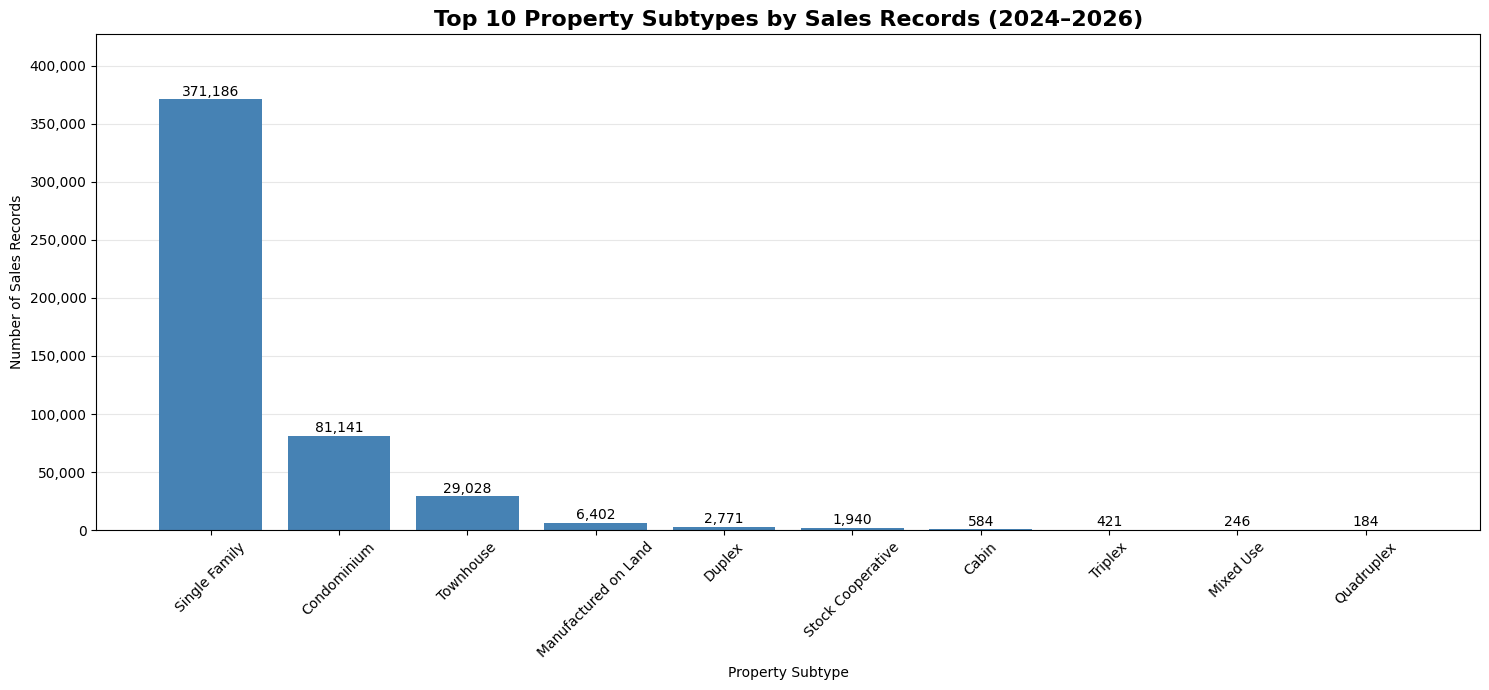

In [27]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Select top 10 property subtypes by number of sales
top10_sales = (
    property_summary
    .dropna(subset=["PropertySubType"])
    .nlargest(10, "TotalSales")
    .copy()
)

# Make property subtype names easier to read
top10_sales["PropertySubType"] = (
    top10_sales["PropertySubType"].replace({
        "SingleFamilyResidence": "Single Family",
        "ManufacturedOnLand": "Manufactured on Land",
        "StockCooperative": "Stock Cooperative",
        "MixedUse": "Mixed Use"
    })
)

# Create vertical bar chart
fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.bar(
    top10_sales["PropertySubType"],
    top10_sales["TotalSales"],
    color="steelblue"
)

# Add sales numbers above each bar
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 3000,
        f"{int(height):,}",
        ha="center",
        fontsize=10
    )

# Chart formatting
ax.set_title(
    "Top 10 Property Subtypes by Sales Records (2024–2026)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Property Subtype")
ax.set_ylabel("Number of Sales Records")

ax.tick_params(axis="x", rotation=45)

ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(0, top10_sales["TotalSales"].max() * 1.15)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save graph
plt.savefig(
    "week6_top10_property_subtype_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

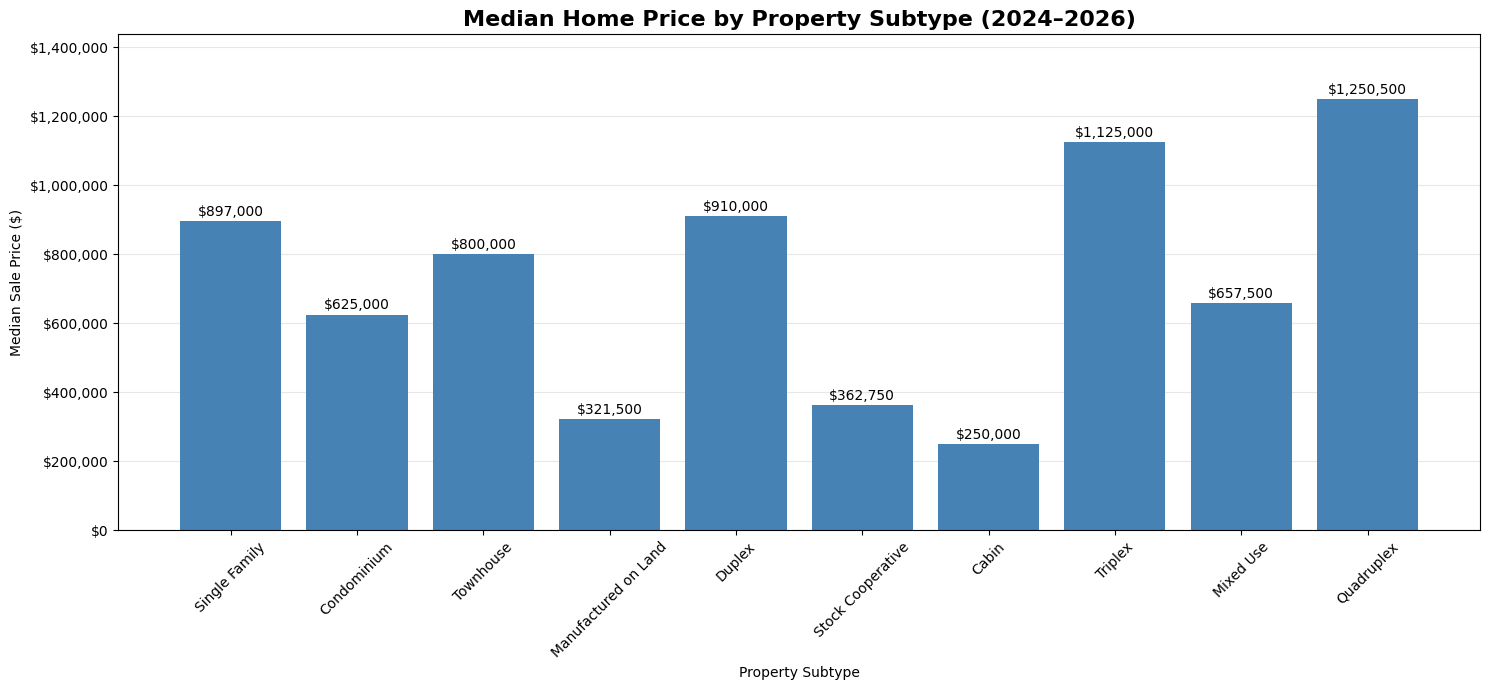

In [28]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Select the 10 property subtypes with the most sales
top10_price = (
    property_summary
    .dropna(subset=["PropertySubType"])
    .nlargest(10, "TotalSales")
    .copy()
)

# Make subtype names easier to read
top10_price["PropertySubType"] = top10_price["PropertySubType"].replace({
    "SingleFamilyResidence": "Single Family",
    "ManufacturedOnLand": "Manufactured on Land",
    "StockCooperative": "Stock Cooperative",
    "MixedUse": "Mixed Use"
})

# Create vertical bar chart
fig, ax = plt.subplots(figsize=(15, 7))

bars = ax.bar(
    top10_price["PropertySubType"],
    top10_price["MedianClosePrice"],
    color="steelblue"
)

# Add median prices above bars
for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 15000,
        f"${height:,.0f}",
        ha="center",
        fontsize=10
    )

# Chart formatting
ax.set_title(
    "Median Home Price by Property Subtype (2024–2026)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Property Subtype")
ax.set_ylabel("Median Sale Price ($)")

ax.tick_params(axis="x", rotation=45)

ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

ax.set_ylim(0, top10_price["MedianClosePrice"].max() * 1.15)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save graph
plt.savefig(
    "week6_top10_median_home_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

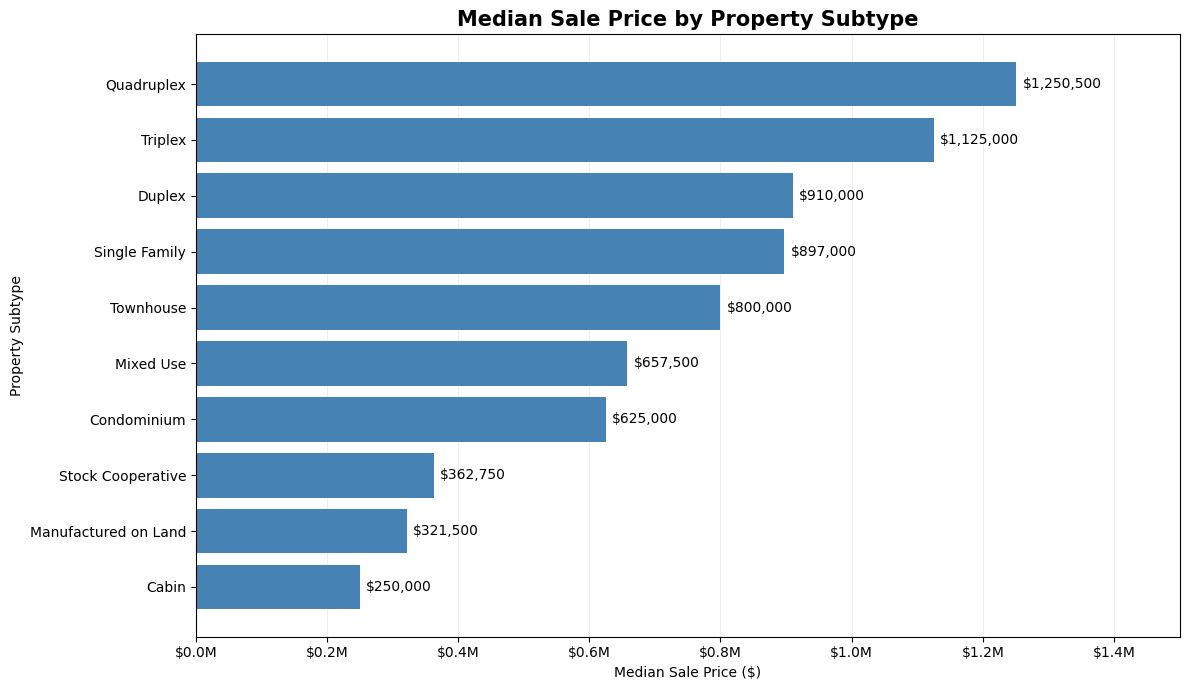

In [22]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Select the 10 most common known property subtypes
top10 = (
    property_summary
    .dropna(subset=["PropertySubType"])
    .nlargest(10, "TotalSales")
    .copy()
)

# Make subtype names easier to read
top10["PropertySubType"] = top10["PropertySubType"].replace({
    "SingleFamilyResidence": "Single Family",
    "ManufacturedOnLand": "Manufactured on Land",
    "StockCooperative": "Stock Cooperative",
    "MixedUse": "Mixed Use"
})

# Sort by median price
top10 = top10.sort_values("MedianClosePrice")

# Create chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top10["PropertySubType"],
    top10["MedianClosePrice"],
    color="steelblue"
)

# Add dollar labels
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 10000,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center"
    )

ax.set_title(
    "Median Sale Price by Property Subtype",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Median Sale Price ($)")
ax.set_ylabel("Property Subtype")

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"${x/1e6:.1f}M")
)

ax.set_xlim(0, top10["MedianClosePrice"].max() * 1.2)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "week6_median_sale_price.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

top10 = (
    property_summary
    .dropna(subset=["PropertySubType"])
    .nlargest(10, "TotalSales")
    .copy()
)

top10["PropertySubType"] = top10["PropertySubType"].replace({
    "SingleFamilyResidence": "Single Family",
    "ManufacturedOnLand": "Manufactured on Land",
    "StockCooperative": "Stock Cooperative",
    "MixedUse": "Mixed Use"
})

print("Selected property subtypes:")
display(top10[["PropertySubType", "TotalSales"]])

Selected property subtypes:


,PropertySubType,TotalSales
14,Single Family,371186
3,Condominium,81141
18,Townhouse,29028
9,Manufactured on Land,6402
5,Duplex,2771
15,Stock Cooperative,1940
1,Cabin,584
19,Triplex,421
10,Mixed Use,246
13,Quadruplex,184


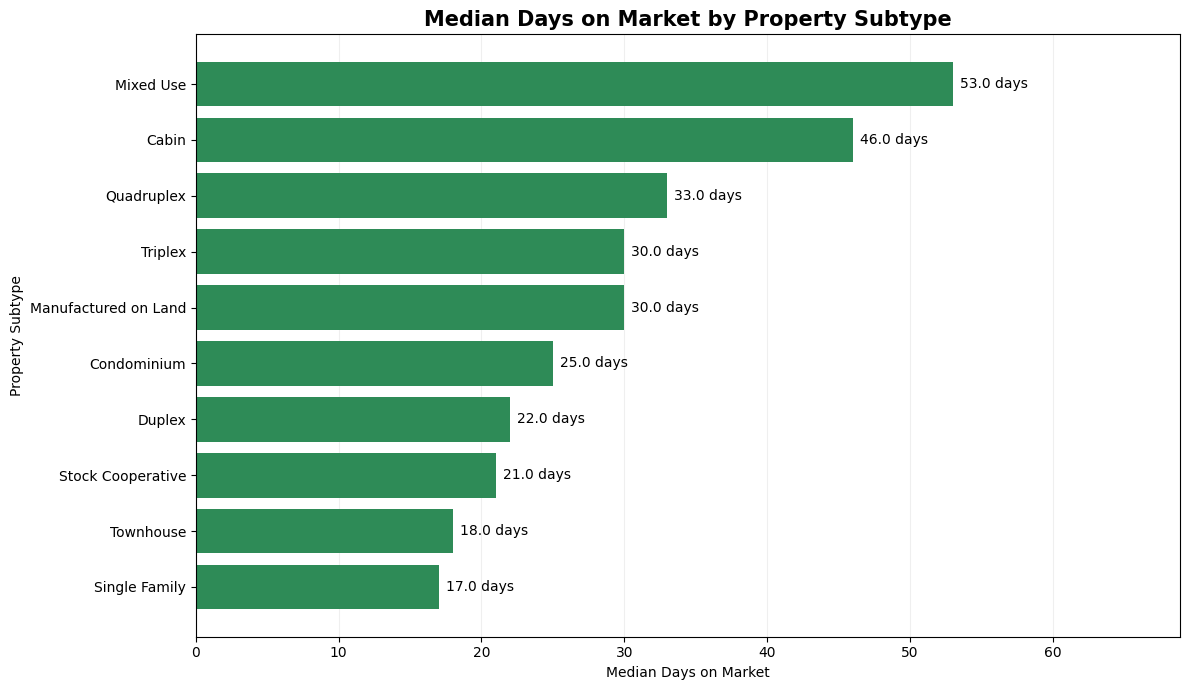

In [24]:
# Sort by median days on market
chart_data = top10.sort_values("MedianDaysOnMarket")

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    chart_data["PropertySubType"],
    chart_data["MedianDaysOnMarket"],
    color="seagreen"
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.1f} days",
        va="center"
    )

ax.set_title(
    "Median Days on Market by Property Subtype",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Median Days on Market")
ax.set_ylabel("Property Subtype")
ax.set_xlim(0, chart_data["MedianDaysOnMarket"].max() * 1.3)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("week6_median_days_on_market.png", dpi=300, bbox_inches="tight")
plt.show()

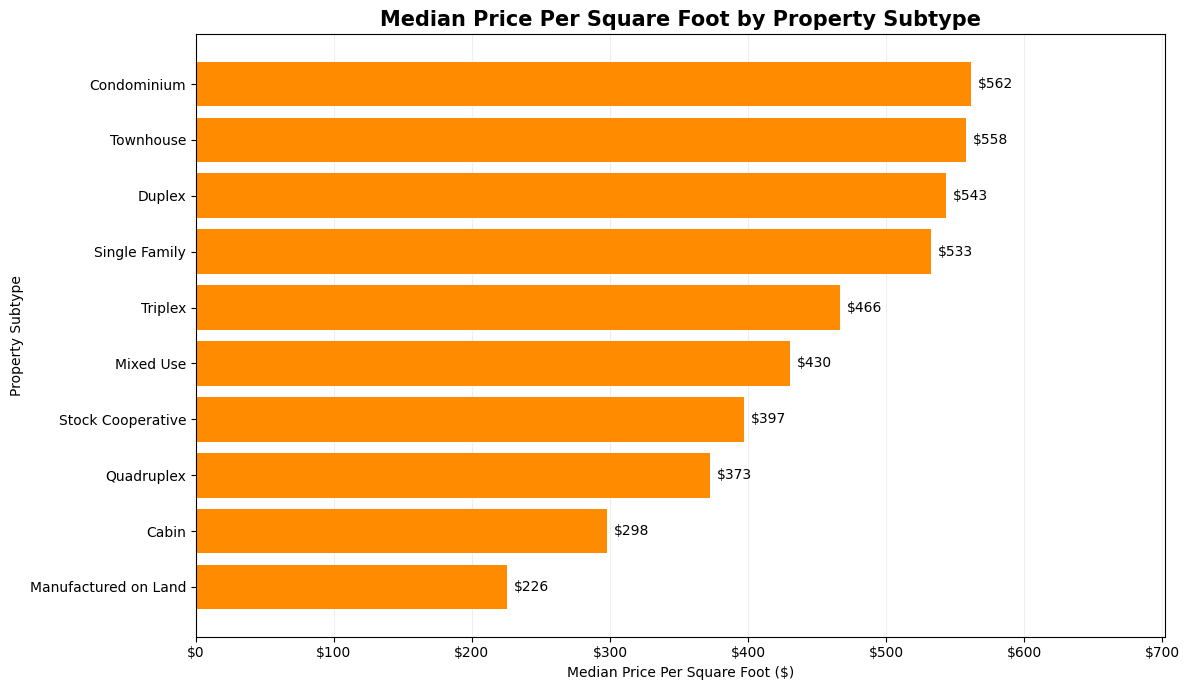

In [25]:
chart_data = top10.sort_values("MedianPricePerSqFt")

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    chart_data["PropertySubType"],
    chart_data["MedianPricePerSqFt"],
    color="darkorange"
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 5,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center"
    )

ax.set_title(
    "Median Price Per Square Foot by Property Subtype",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Median Price Per Square Foot ($)")
ax.set_ylabel("Property Subtype")
ax.set_xlim(0, chart_data["MedianPricePerSqFt"].max() * 1.25)

ax.xaxis.set_major_formatter(
    ticker.StrMethodFormatter("${x:,.0f}")
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("week6_median_price_per_sqft.png", dpi=300, bbox_inches="tight")
plt.show()

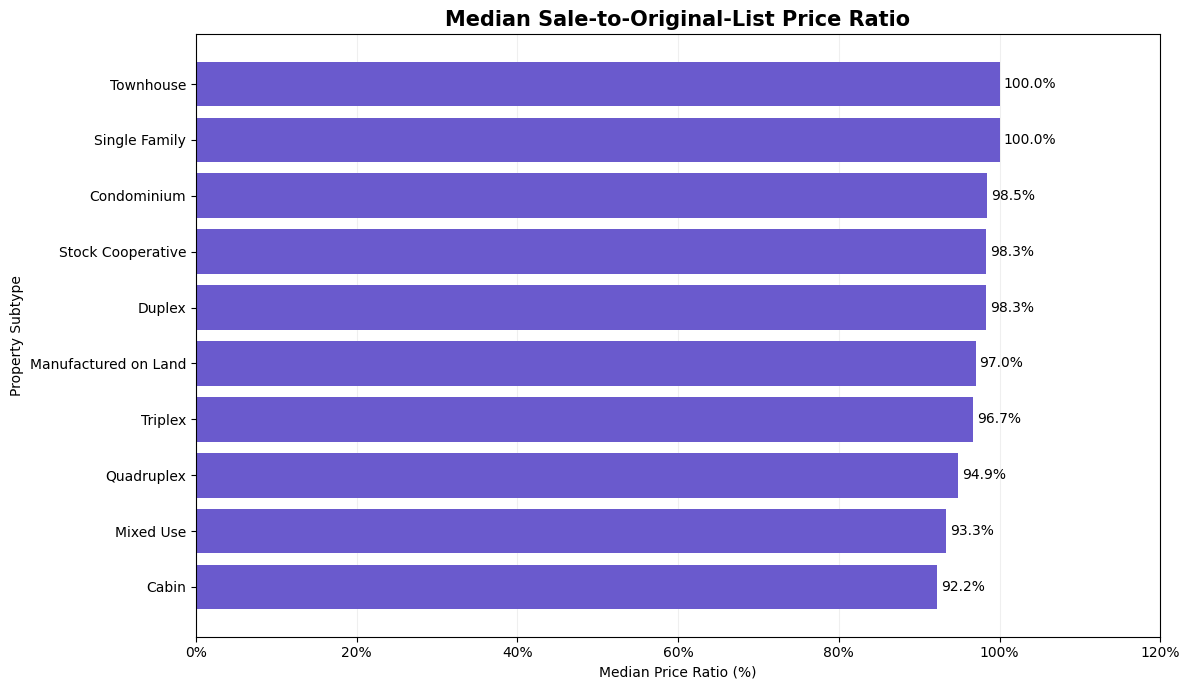

In [26]:
chart_data = top10.sort_values("MedianPriceRatio")

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    chart_data["PropertySubType"],
    chart_data["MedianPriceRatio"] * 100,
    color="slateblue"
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center"
    )

ax.set_title(
    "Median Sale-to-Original-List Price Ratio",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Median Price Ratio (%)")
ax.set_ylabel("Property Subtype")

ax.set_xlim(0, chart_data["MedianPriceRatio"].max() * 120)

ax.xaxis.set_major_formatter(
    ticker.PercentFormatter(xmax=100)
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("week6_median_price_ratio.png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
# Group properties by County and MLS Area

mls_summary = (
    sold_w6.groupby(
        ["CountyOrParish", "MLSAreaMajor"],
        dropna=False
    )
    .agg(
        TotalSales=("ClosePrice", "size"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianPricePerSqFt=("PricePerSqFt_Valid", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

# Display the 20 MLS areas with the most sales
display(mls_summary.head(20))

,CountyOrParish,MLSAreaMajor,TotalSales,MedianClosePrice,MedianPricePerSqFt,MedianDaysOnMarket,MedianPriceRatio
875,Riverside,SRCAR - Southwest Riverside County,24157,589000.0,294.117647,24.0,0.995763
17,Contra Costa,NaN,21995,825000.0,521.783181,14.0,1.000000
3,Alameda,NaN,21374,1128000.0,696.540211,14.0,1.019597
1205,Santa Clara,699 - Not Defined,19479,1600000.0,970.496894,10.0,1.021172
1167,San Mateo,699 - Not Defined,7899,1730000.0,1061.061061,12.0,1.013514
817,Riverside,252 - Riverside,6272,660000.0,378.592736,20.0,1.000000
9,Butte,NaN,4896,399000.0,267.398418,23.0,0.982301
598,Monterey,699 - Not Defined,4576,915000.0,593.126994,19.0,0.979879
813,Riverside,248 - Corona,3987,757800.0,396.551724,22.0,0.994109
426,Los Angeles,LAC - Lancaster,3653,475000.0,270.588235,25.0,1.000000


In [30]:
# Keep only MLS areas with meaningful names

mls_valid = mls_summary.dropna(
    subset=["MLSAreaMajor"]
).copy()

# Remove undefined MLS areas
mls_valid = mls_valid[
    ~mls_valid["MLSAreaMajor"]
    .astype(str)
    .str.contains(
        "Not Defined|Unknown|Unspecified",
        case=False,
        na=False
    )
].copy()

# Select top 10 areas by sales records
top10_mls = mls_valid.nlargest(
    10, "TotalSales"
).copy()

display(top10_mls)

,CountyOrParish,MLSAreaMajor,TotalSales,MedianClosePrice,MedianPricePerSqFt,MedianDaysOnMarket,MedianPriceRatio
875,Riverside,SRCAR - Southwest Riverside County,24157,589000.0,294.117647,24.0,0.995763
817,Riverside,252 - Riverside,6272,660000.0,378.592736,20.0,1.000000
813,Riverside,248 - Corona,3987,757800.0,396.551724,22.0,0.994109
426,Los Angeles,LAC - Lancaster,3653,475000.0,270.588235,25.0,1.000000
1018,San Bernardino,VIC - Victorville,3527,439900.0,238.123167,25.0,1.000000
819,Riverside,263 - Banning/Beaumont/Cherry Valley,3487,499000.0,260.010400,30.0,0.992174
894,San Bernardino,274 - San Bernardino,3430,500000.0,354.068802,20.0,1.000000
818,Riverside,259 - Moreno Valley,3176,555000.0,312.435116,18.0,1.000000
911,San Bernardino,686 - Ontario,3126,654077.0,415.152104,20.0,1.000000
886,San Bernardino,264 - Fontana,3045,649469.0,359.461115,18.0,1.000000


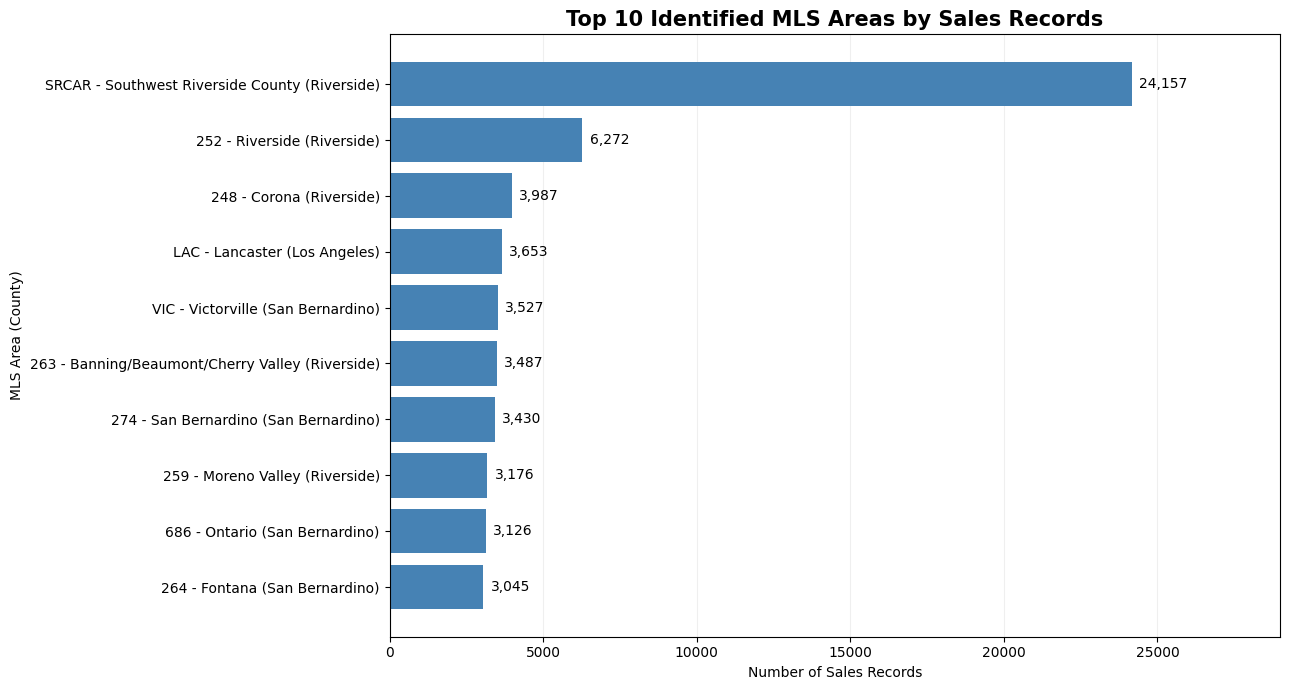

In [31]:
import matplotlib.pyplot as plt

# Sort so the largest bar appears at the top
chart_data = top10_mls.sort_values("TotalSales")

# Include county to distinguish areas with similar names
labels = (
    chart_data["MLSAreaMajor"].astype(str)
    + " (" + chart_data["CountyOrParish"].astype(str) + ")"
)

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    labels,
    chart_data["TotalSales"],
    color="steelblue"
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + top10_mls["TotalSales"].max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center"
    )

ax.set_title(
    "Top 10 Identified MLS Areas by Sales Records",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of Sales Records")
ax.set_ylabel("MLS Area (County)")
ax.set_xlim(0, top10_mls["TotalSales"].max() * 1.2)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "week6_top10_mls_sales.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
listing_office_summary = (
    sold_w6.dropna(subset=["ListOfficeName"])
    .groupby("ListOfficeName")
    .agg(
        TotalSales=("ClosePrice", "size"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

display(listing_office_summary.head(15))

,ListOfficeName,TotalSales,MedianClosePrice,MedianDaysOnMarket,MedianPriceRatio
4200,Compass,35089,1350000.0,14.0,1.000000
4105,Coldwell Banker Realty,22253,1200000.0,16.0,0.994911
9536,Keller Williams Realty,9673,875000.0,15.0,1.000000
6325,First Team Real Estate,6941,960000.0,13.0,1.000000
2012,Berkshire Hathaway HomeServices California Pro...,6258,960000.0,23.0,0.983170
19724,eXp Realty of California Inc,5775,790000.0,19.0,1.000000
14589,Real Broker,5771,850000.0,15.0,1.000000
8341,Intero Real Estate Services,5177,1365000.0,12.0,1.012790
5820,Equity Union,4495,850000.0,28.0,0.979452
19727,"eXp Realty of California, Inc.",4303,755000.0,13.0,1.000000


In [33]:
# Create a normalized brokerage name for comparison
sold_w6["ListOfficeName_Normalized"] = (
    sold_w6["ListOfficeName"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"[.,]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
)

# Check eXp Realty variations
exp_names = (
    sold_w6[
        sold_w6["ListOfficeName_Normalized"]
        .str.contains("exp realty", na=False)
    ]
    .groupby(
        ["ListOfficeName_Normalized", "ListOfficeName"],
        dropna=False
    )
    .size()
    .reset_index(name="Records")
    .sort_values("Records", ascending=False)
)

display(exp_names.head(30))

,ListOfficeName_Normalized,ListOfficeName,Records
24,exp realty of california inc,eXp Realty of California Inc,5775
27,exp realty of california inc,"eXp Realty of California, Inc.",4303
70,exp realty of southern california inc,"eXp Realty of Southern California, Inc.",1293
26,exp realty of california inc,"eXp Realty of California, Inc",1108
38,exp realty of greater los angeles,eXp Realty of Greater Los Angeles,938
7,exp realty of california,eXp Realty of California,914
8,exp realty of california inc,EXP REALTY OF CALIFORNIA INC,835
55,exp realty of southern ca,eXp Realty of Southern CA,692
42,exp realty of greater los angeles inc,"eXp Realty of Greater Los Angeles, Inc.",615
21,exp realty of california inc,Exp Realty of California Inc.,516


In [34]:
listing_office_clean_summary = (
    sold_w6.dropna(
        subset=["ListOfficeName_Normalized"]
    )
    .groupby("ListOfficeName_Normalized")
    .agg(
        TotalSales=("ClosePrice", "size"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

display(listing_office_clean_summary.head(15))

,ListOfficeName_Normalized,TotalSales,MedianClosePrice,MedianDaysOnMarket,MedianPriceRatio
3923,compass,37339,1330000.0,14.0,1.000000
3823,coldwell banker realty,22864,1170000.0,16.0,0.995116
5724,exp realty of california inc,14034,760000.0,17.0,1.000000
9033,keller williams realty,10678,835000.0,15.0,1.000000
5996,first team real estate,7173,950000.0,13.0,1.000000
1771,berkshire hathaway homeservices california pro...,6389,950000.0,23.0,0.983661
13726,real broker,5862,845000.0,15.0,1.000000
7944,intero real estate services,5177,1365000.0,12.0,1.012790
3217,century 21 masters,4746,640000.0,20.0,0.998050
5498,equity union,4495,850000.0,28.0,0.979452


In [35]:
#Normalize buyer office names
sold_w6["BuyerOfficeName_Normalized"] = (
    sold_w6["BuyerOfficeName"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"[.,]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
)

In [36]:
buyer_office_clean_summary = (
    sold_w6.dropna(
        subset=["BuyerOfficeName_Normalized"]
    )
    .groupby("BuyerOfficeName_Normalized")
    .agg(
        TotalSales=("ClosePrice", "size"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianContractToCloseDays=(
            "ContractToCloseDays_Valid", "median"
        ),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

display(buyer_office_clean_summary.head(15))

,BuyerOfficeName_Normalized,TotalSales,MedianClosePrice,MedianContractToCloseDays,MedianPriceRatio
4442,compass,34955,1315000.0,25.0,1.000000
4333,coldwell banker realty,18291,1175000.0,26.0,0.994400
6457,exp realty of california inc,16545,759000.0,28.0,1.000000
13309,nonmember mrml,11164,500000.0,31.0,0.985913
10140,keller williams realty,8570,799994.5,28.0,0.995000
15509,real broker,7672,800000.0,27.0,0.997371
6824,first team real estate,6508,895000.0,28.0,1.000000
2017,berkshire hathaway homeservices california pro...,4906,984500.0,28.0,0.985144
15987,redfin corporation,4212,830000.0,28.0,0.988750
8941,intero real estate services,4167,1325000.0,25.0,1.009091


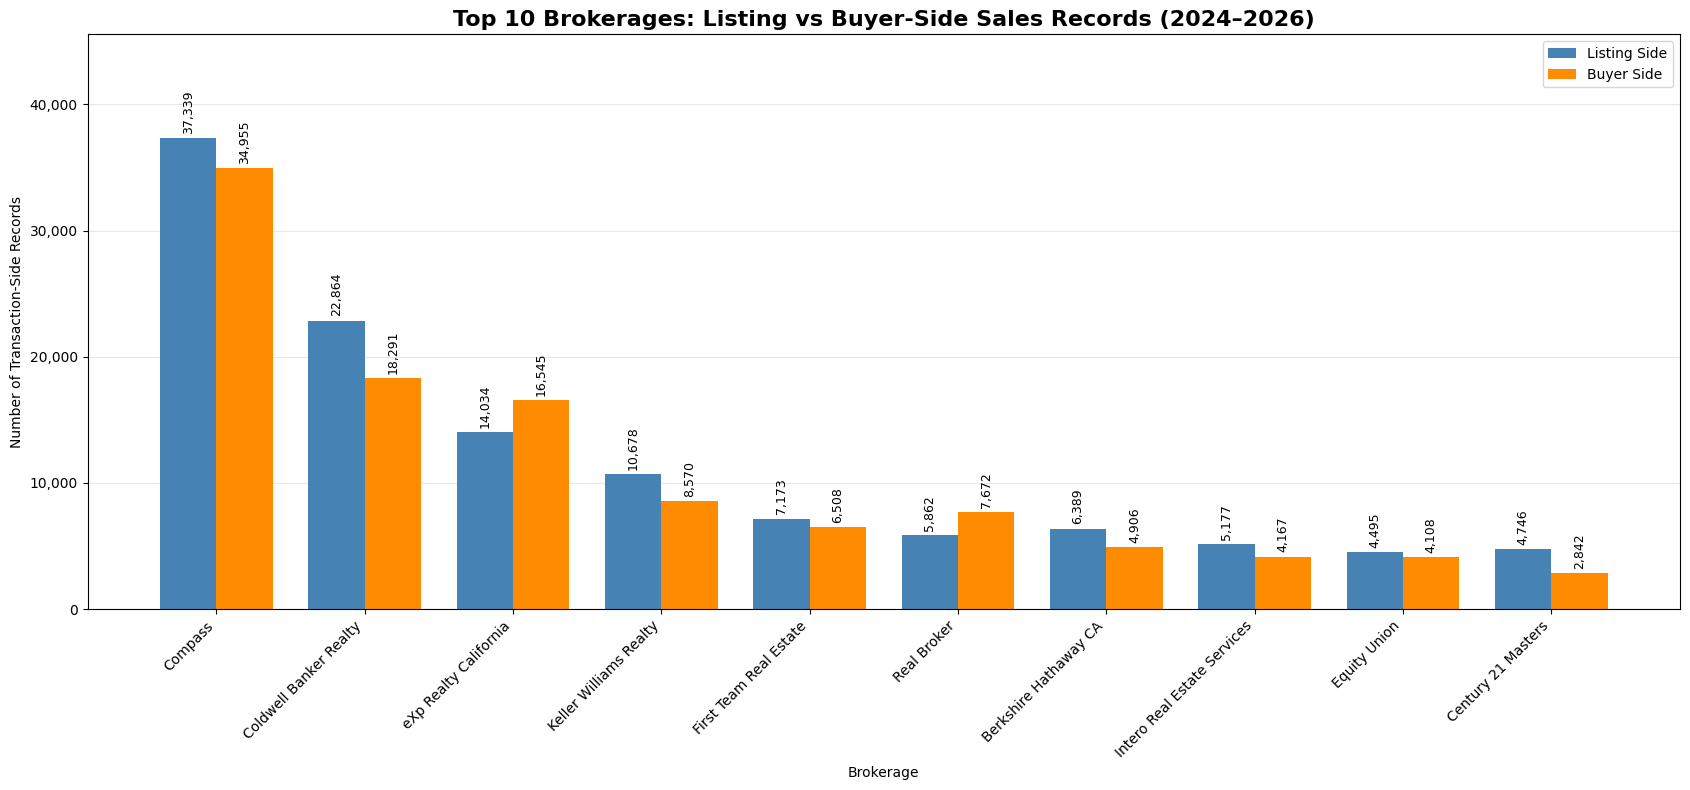

,DisplayName,ListingSales,BuyerSales
5204,Compass,37339.0,34955.0
5076,Coldwell Banker Realty,22864.0,18291.0
7603,eXp Realty California,14034.0,16545.0
12057,Keller Williams Realty,10678.0,8570.0
8016,First Team Real Estate,7173.0,6508.0
18458,Real Broker,5862.0,7672.0
2365,Berkshire Hathaway CA,6389.0,4906.0
10548,Intero Real Estate Services,5177.0,4167.0
7302,Equity Union,4495.0,4108.0
4259,Century 21 Masters,4746.0,2842.0


In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# 1. Combine listing and buyer office summaries
office_comparison = pd.merge(
    listing_office_clean_summary[
        ["ListOfficeName_Normalized", "TotalSales"]
    ].rename(columns={
        "ListOfficeName_Normalized": "Brokerage",
        "TotalSales": "ListingSales"
    }),
    buyer_office_clean_summary[
        ["BuyerOfficeName_Normalized", "TotalSales"]
    ].rename(columns={
        "BuyerOfficeName_Normalized": "Brokerage",
        "TotalSales": "BuyerSales"
    }),
    on="Brokerage",
    how="outer"
).fillna({"ListingSales": 0, "BuyerSales": 0})

# 2. Exclude non-specific brokerage names
office_comparison = office_comparison[
    ~office_comparison["Brokerage"].isin([
        "nonmember mrml",
        "none mrml"
    ])
].copy()

# 3. Select top 10 by combined transaction-side records
office_comparison["CombinedSides"] = (
    office_comparison["ListingSales"]
    + office_comparison["BuyerSales"]
)

top10_offices = (
    office_comparison
    .nlargest(10, "CombinedSides")
    .copy()
)

# 4. Improve brokerage labels
top10_offices["DisplayName"] = (
    top10_offices["Brokerage"]
    .str.title()
    .replace({
        "Exp Realty Of California Inc":
            "eXp Realty California",
        "Berkshire Hathaway Homeservices California Properties":
            "Berkshire Hathaway CA"
    })
)

# 5. Create grouped vertical bar chart
import numpy as np

x = np.arange(len(top10_offices))
width = 0.38

fig, ax = plt.subplots(figsize=(17, 8))

bars1 = ax.bar(
    x - width / 2,
    top10_offices["ListingSales"],
    width,
    label="Listing Side",
    color="steelblue"
)

bars2 = ax.bar(
    x + width / 2,
    top10_offices["BuyerSales"],
    width,
    label="Buyer Side",
    color="darkorange"
)

# 6. Add numbers above bars
for bars in [bars1, bars2]:
    ax.bar_label(
        bars,
        labels=[f"{v:,.0f}" for v in bars.datavalues],
        padding=3,
        fontsize=9,
        rotation=90
    )

# 7. Chart formatting
ax.set_title(
    "Top 10 Brokerages: Listing vs Buyer-Side Sales Records (2024–2026)",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Brokerage")
ax.set_ylabel("Number of Transaction-Side Records")

ax.set_xticks(x)
ax.set_xticklabels(
    top10_offices["DisplayName"],
    rotation=45,
    ha="right"
)

ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(
    0,
    max(
        top10_offices["ListingSales"].max(),
        top10_offices["BuyerSales"].max()
    ) * 1.22
)

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# 8. Save chart
plt.savefig(
    "week6_listing_vs_buyer_top10.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Display comparison table
display(
    top10_offices[
        ["DisplayName", "ListingSales", "BuyerSales"]
    ]
)

In [38]:
print(
    "Total unique brokerages:",
    office_comparison["Brokerage"].nunique()
)

print(
    "Unique listing offices:",
    sold_w6["ListOfficeName_Normalized"].nunique()
)

print(
    "Unique buyer offices:",
    sold_w6["BuyerOfficeName_Normalized"].nunique()
)

Total unique brokerages: 25165
Unique listing offices: 18818
Unique buyer offices: 21166


In [39]:
listing_names = set(
    sold_w6["ListOfficeName_Normalized"].dropna()
)

buyer_names = set(
    sold_w6["BuyerOfficeName_Normalized"].dropna()
)

both_sides = listing_names & buyer_names

print("Offices appearing on both sides:", len(both_sides))
print("Listing side only:", len(listing_names - buyer_names))
print("Buyer side only:", len(buyer_names - listing_names))

Offices appearing on both sides: 14817
Listing side only: 4001
Buyer side only: 6349


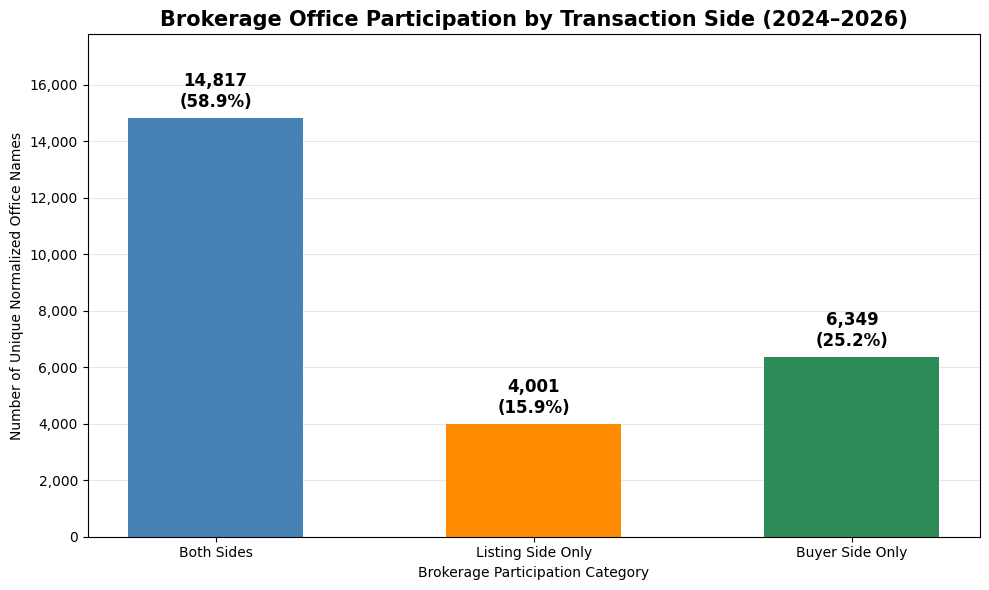

In [40]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Brokerage participation counts
categories = [
    "Both Sides",
    "Listing Side Only",
    "Buyer Side Only"
]

counts = [14817, 4001, 6349]

colors = ["steelblue", "darkorange", "seagreen"]

# Create vertical bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    categories,
    counts,
    color=colors,
    width=0.55
)

# Add counts and percentages above each bar
total = sum(counts)

for bar, count in zip(bars, counts):
    percentage = count / total * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 250,
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# Chart formatting
ax.set_title(
    "Brokerage Office Participation by Transaction Side (2024–2026)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Brokerage Participation Category")
ax.set_ylabel("Number of Unique Normalized Office Names")

ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(0, max(counts) * 1.2)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save chart
plt.savefig(
    "week6_brokerage_participation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Brokerage Participation Analysis**

The analysis identified 25,167 distinct normalized brokerage office names in the residential sold dataset. Of these, 14,817 (58.9%) appeared on both the listing and buyer sides, 4,001 (15.9%) appeared only on the listing side, and 6,349 (25.2%) appeared only on the buyer side.

The results indicate that most recorded office names participate on both sides of real estate transactions. However, a substantial number appear exclusively on one side within the analyzed dataset. These findings describe recorded office-name participation rather than the total number of distinct brokerage companies.

In [41]:
# Find geographic columns in the dataset

geo_columns = [
    col for col in sold_w6.columns
    if any(word in col.lower() for word in [
        "latitude", "longitude", "postal",
        "zip", "county", "district"
    ])
]

print("Geographic columns found:")
print(geo_columns)

# Check latitude and longitude availability
if {"Latitude", "Longitude"}.issubset(sold_w6.columns):

    print("\nMissing geographic coordinates:")

    print(
        sold_w6[["Latitude", "Longitude"]]
        .isna()
        .sum()
    )

    print("\nSample coordinates:")

    display(
        sold_w6[
            ["CountyOrParish", "Latitude", "Longitude"]
        ].head(10)
    )

Geographic columns found:
['Latitude', 'Longitude', 'CountyOrParish', 'HighSchoolDistrict', 'PostalCode']

Missing geographic coordinates:
Latitude     4796
Longitude    4796
dtype: int64

Sample coordinates:


,CountyOrParish,Latitude,Longitude
0,San Mateo,37.566106,-122.327954
1,San Diego,32.659315,-117.096922
2,San Diego,32.659284,-117.097174
3,San Luis Obispo,35.277199,-120.646786
4,Mendocino,39.419080,-123.814842
5,Santa Clara,37.325454,-121.780303
6,San Diego,32.715089,-117.170568
7,Los Angeles,34.070215,-118.258618
8,Los Angeles,34.107850,-118.219273
9,San Mateo,37.589762,-122.399887


In [42]:
from pathlib import Path
import zipfile

# Find uploaded ZIP files
zip_files = list(Path("/content").glob("*.zip"))

for file in zip_files:
    print("ZIP file:", file.name)

    with zipfile.ZipFile(file) as archive:
        print("Contents:")
        for name in archive.namelist()[:20]:
            print(" ", name)

ZIP file: DistrictAreas2425 (1).zip
Contents:
  DistrictAreas2425.prj
  DistrictAreas2425.xml
  DistrictAreas2425.shp
  DistrictAreas2425.shx
  DistrictAreas2425.cpg
  DistrictAreas2425.dbf


In [43]:
%pip install -q geopandas

In [44]:
import geopandas as gpd
import zipfile
from pathlib import Path

# 1. Locate your ZIP file
zip_path = "/content/DistrictAreas2425 (1).zip"

# 2. Extract the shapefile
extract_folder = Path("/content/CA_School_Districts")
extract_folder.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_folder)

print("Extraction complete!")

# 3. Load school district boundaries
shapefile_path = extract_folder / "DistrictAreas2425.shp"

districts = gpd.read_file(shapefile_path)

# 4. Inspect the data
print("\nNumber of district polygons:", len(districts))

print("\nCoordinate reference system:")
print(districts.crs)

print("\nAvailable columns:")
print(districts.columns.tolist())

print("\nSample records:")
display(districts.drop(columns="geometry").head(10))

Extraction complete!

Number of district polygons: 937

Coordinate reference system:
EPSG:3857

Available columns:
['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName', 'DistrictNa', 'DistrictTy', 'GradeLow', 'GradeHigh', 'GradeLowCe', 'GradeHighC', 'AssistStat', 'CongressUS', 'SenateCA', 'AssemblyCA', 'UpdateNote', 'EnrollTota', 'EnrollChar', 'EnrollNonC', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount', 'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct', 'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount', 'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount', 'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAre', 'Shape__Are', 'Shape__Len', 'geometry']

Sample records:


,OBJECTID,Year,FedID,CDCode,CDSCode,CountyName,DistrictNa,DistrictTy,GradeLow,GradeHigh,...,HOMpct,MIGcount,MIGpct,SWDcount,SWDpct,SEDcount,SEDpct,DistrctAre,Shape__Are,Shape__Len
0,1,2024-25,0601770,0161119,01611190000000,Alameda,Alameda Unified,Unified,PK,12,...,0.7,0,0.0,1356,12.6,3958,36.7,11.248939,4.755489e+07,56522.982683
1,2,2024-25,0601860,0161127,01611270000000,Alameda,Albany City Unified,Unified,PK,12,...,0.6,0,0.0,357,9.7,1184,32.1,1.789984,7.096327e+06,12696.382797
2,3,2024-25,0604740,0161143,01611430000000,Alameda,Berkeley Unified,Unified,PK,12,...,2.1,0,0.0,1111,12.1,2686,29.3,10.434329,4.364648e+07,43695.341538
3,4,2024-25,0607800,0161150,01611500000000,Alameda,Castro Valley Unified,Unified,PK,12,...,1.3,0,0.0,1113,11.6,3728,39.0,66.885571,2.838285e+08,142492.767565
4,5,2024-25,0612630,0161168,01611680000000,Alameda,Emery Unified,Unified,PK,12,...,2.5,0,0.0,81,13.7,412,69.8,1.273929,5.363392e+06,13741.272894
5,6,2024-25,0614400,0161176,01611760000000,Alameda,Fremont Unified,Unified,PK,12,...,0.8,36,0.1,3481,10.5,10059,30.4,78.011843,3.210190e+08,163452.273563
6,7,2024-25,0616740,0161192,01611920000000,Alameda,Hayward Unified,Unified,PK,12,...,1.4,329,1.6,2729,13.7,15128,75.8,34.342811,1.419818e+08,82372.310062
7,8,2024-25,0622110,0161200,01612000000000,Alameda,Livermore Valley Joint Unified,Unified,PK,12,...,1.1,91,0.7,1945,15.0,2847,22.0,264.481255,1.103915e+09,206081.113757
8,9,2024-25,0626130,0161218,01612180000000,Alameda,Mountain House Elementary,Elementary,KG,08,...,0.0,0,0.0,1,7.1,7,50.0,29.614871,1.247966e+08,55768.468465
9,10,2024-25,0627060,0161234,01612340000000,Alameda,Newark Unified,Unified,KG,12,...,4.7,27,0.6,658,14.1,1966,42.1,13.987668,5.814658e+07,39693.104863


In [45]:
# Count school districts by type

print("School districts by type:")

display(
    districts["DistrictTy"]
    .value_counts(dropna=False)
    .reset_index()
)

School districts by type:


,DistrictTy,count
0,Elementary,516
1,Unified,345
2,High,76


In [46]:
import pandas as pd

# Convert coordinates to numeric
sold_w6["Latitude"] = pd.to_numeric(
    sold_w6["Latitude"], errors="coerce"
)

sold_w6["Longitude"] = pd.to_numeric(
    sold_w6["Longitude"], errors="coerce"
)

# Check plausible California coordinate ranges
valid_geo = (
    sold_w6["Latitude"].between(32, 42.1)
    & sold_w6["Longitude"].between(-125, -114)
)

print("Total sold records:", len(sold_w6))
print("Records with plausible CA coordinates:", valid_geo.sum())
print("Missing or implausible coordinates:", (~valid_geo).sum())

Total sold records: 495243
Records with plausible CA coordinates: 490332
Missing or implausible coordinates: 4911


In [47]:
import geopandas as gpd

# Keep a stable identifier for each original record
sold_w6["PropertyRowID"] = range(len(sold_w6))

# Select properties with plausible California coordinates
sold_geo = sold_w6.loc[valid_geo].copy()

# Convert latitude and longitude into geographic points
sold_geo = gpd.GeoDataFrame(
    sold_geo,
    geometry=gpd.points_from_xy(
        sold_geo["Longitude"],
        sold_geo["Latitude"]
    ),
    crs="EPSG:4326"
)

# Convert to the same CRS as school district polygons
sold_geo = sold_geo.to_crs(districts.crs)

print("Properties converted to geographic points:", len(sold_geo))
print("Property CRS:", sold_geo.crs)
print("District CRS:", districts.crs)

display(
    sold_geo[
        ["PropertyRowID", "Latitude", "Longitude", "geometry"]
    ].head()
)

Properties converted to geographic points: 490332
Property CRS: EPSG:3857
District CRS: EPSG:3857


,PropertyRowID,Latitude,Longitude,geometry
0,0,37.566106,-122.327954,POINT (-13617485.56 4518311.233)
1,1,32.659315,-117.096922,POINT (-13035169.686 3850170.612)
2,2,32.659284,-117.097174,POINT (-13035197.839 3850166.381)
3,3,35.277199,-120.646786,POINT (-13430338.783 4201615.479)
4,4,39.419080,-123.814842,POINT (-13783005.164 4781880.21)


In [48]:
# Elementary or unified district boundaries
elementary_districts = districts[
    districts["DistrictTy"].isin(["Elementary", "Unified"])
][
    ["DistrictNa", "DistrictTy", "CDCode", "geometry"]
].copy()

# High school or unified district boundaries
high_districts = districts[
    districts["DistrictTy"].isin(["High", "Unified"])
][
    ["DistrictNa", "DistrictTy", "CDCode", "geometry"]
].copy()

print("Elementary/Unified polygons:", len(elementary_districts))
print("High/Unified polygons:", len(high_districts))

Elementary/Unified polygons: 861
High/Unified polygons: 421


In [49]:
# Select property IDs and geographic points
property_points = sold_geo[
    ["PropertyRowID", "geometry"]
].copy()

# Match properties to elementary/unified districts
elementary_matches = gpd.sjoin(
    property_points,
    elementary_districts,
    how="left",
    predicate="intersects"
)

# Match properties to high/unified districts
high_matches = gpd.sjoin(
    property_points,
    high_districts,
    how="left",
    predicate="intersects"
)

print("Original geographic properties:", len(property_points))
print("Elementary join rows:", len(elementary_matches))
print("High school join rows:", len(high_matches))

# Check multiple matches and unmatched properties
for label, matches in [
    ("Elementary", elementary_matches),
    ("High school", high_matches)
]:
    counts = matches.groupby(
        "PropertyRowID"
    )["index_right"].count()

    print(f"\n{label}:")
    print("Multiple matches:", (counts > 1).sum())
    print("No district match:", (counts == 0).sum())

Original geographic properties: 490332
Elementary join rows: 492334
High school join rows: 490332

Elementary:
Multiple matches: 2002
No district match: 142

High school:
Multiple matches: 0
No district match: 593


In [50]:
# Count how many district matches each property received
elementary_counts = (
    elementary_matches
    .groupby("PropertyRowID")["index_right"]
    .count()
)

high_counts = (
    high_matches
    .groupby("PropertyRowID")["index_right"]
    .count()
)

print(
    "Properties with multiple elementary matches:",
    (elementary_counts > 1).sum()
)

print(
    "Properties with multiple high school matches:",
    (high_counts > 1).sum()
)

print(
    "Properties without elementary district:",
    (elementary_counts == 0).sum()
)

print(
    "Properties without high school district:",
    (high_counts == 0).sum()
)

Properties with multiple elementary matches: 2002
Properties with multiple high school matches: 0
Properties without elementary district: 142
Properties without high school district: 593


In [51]:
# Find properties with multiple elementary matches
duplicate_ids = (
    elementary_matches
    .groupby("PropertyRowID")["index_right"]
    .count()
)

duplicate_ids = duplicate_ids[
    duplicate_ids > 1
].index

# Display examples of overlapping matches
duplicate_examples = (
    elementary_matches[
        elementary_matches["PropertyRowID"].isin(
            duplicate_ids
        )
    ][
        ["PropertyRowID", "DistrictNa", "DistrictTy", "CDCode"]
    ]
    .sort_values("PropertyRowID")
)

display(duplicate_examples.head(20))

,PropertyRowID,DistrictNa,DistrictTy,CDCode
216,216,Montecito Union Elementary,Elementary,4269252
216,216,Santa Barbara Unified,Unified,4276786
365,365,Paso Robles Joint Unified,Unified,4075457
365,365,San Miguel Joint Union,Elementary,4068825
1281,1281,Garvey Elementary,Elementary,1964550
1281,1281,Alhambra Unified,Unified,1975713
1702,1702,Robla Elementary,Elementary,3467421
1702,1702,Twin Rivers Unified,Unified,3476505
2201,2201,Santa Paula Unified,Unified,5676828
2201,2201,Mupu Elementary,Elementary,5672504


In [52]:
overlap_types = (
    elementary_matches[
        elementary_matches["PropertyRowID"].isin(duplicate_ids)
    ]
    .groupby("PropertyRowID")["DistrictTy"]
    .agg(
        lambda x: " + ".join(
            sorted(x.dropna().unique())
        )
    )
    .value_counts()
)

print("District type combinations:")
display(overlap_types)

District type combinations:


,count
DistrictTy,
Elementary + Unified,2002


In [53]:
# Get the district codes involved in overlapping matches
overlap_codes = (
    elementary_matches.loc[
        elementary_matches["PropertyRowID"].isin(duplicate_ids),
        "CDCode"
    ]
    .dropna()
    .unique()
)

# Inspect the grade ranges of those districts
overlap_district_details = (
    districts[
        districts["CDCode"].isin(overlap_codes)
    ][
        [
            "DistrictNa",
            "DistrictTy",
            "GradeLow",
            "GradeHigh",
            "CDCode"
        ]
    ]
    .drop_duplicates()
    .sort_values(["DistrictTy", "DistrictNa"])
)

print("Number of districts involved:", len(overlap_district_details))

display(overlap_district_details.head(20))

Number of districts involved: 84


,DistrictNa,DistrictTy,GradeLow,GradeHigh,CDCode
854,Alta Vista Elementary,Elementary,PK,12,5471811
321,Bass Lake Joint Union Elementary,Elementary,KG,08,2065185
76,Big Creek Elementary,Elementary,PK,08,1062026
906,Briggs Elementary,Elementary,KG,08,5672447
856,Burton Elementary,Elementary,PK,12,5471837
106,Capay Joint Union Elementary,Elementary,KG,08,1162554
605,Cayucos Elementary,Elementary,KG,08,4068726
794,Chatom Union,Elementary,PK,08,5071050
387,Chualar Union,Elementary,KG,08,2765995
844,Coffee Creek Elementary,Elementary,KG,08,5371670


In [54]:
# Count actual district matches per property
elementary_match_counts = (
    elementary_matches
    .groupby("PropertyRowID")["index_right"]
    .count()
)

# Keep properties with exactly one district match
single_match_ids = elementary_match_counts[
    elementary_match_counts == 1
].index

# Create a lookup with only unambiguous matches
elementary_lookup = (
    elementary_matches[
        elementary_matches["PropertyRowID"].isin(single_match_ids)
    ][["PropertyRowID", "DistrictNa", "DistrictTy", "CDCode"]]
    .rename(columns={
        "DistrictNa": "ElementaryDistrict",
        "DistrictTy": "ElementaryDistrictType",
        "CDCode": "ElementaryDistrictCode"
    })
    .copy()
)

print("Properties with one elementary district:",
      len(elementary_lookup))

print("Properties with ambiguous elementary districts:",
      (elementary_match_counts > 1).sum())

print("Properties without elementary district:",
      (elementary_match_counts == 0).sum())

print("Duplicate IDs in lookup:",
      elementary_lookup["PropertyRowID"].duplicated().sum())

Properties with one elementary district: 488188
Properties with ambiguous elementary districts: 2002
Properties without elementary district: 142
Duplicate IDs in lookup: 0


In [55]:
# Keep properties with a valid high school district match
high_lookup = (
    high_matches[
        high_matches["index_right"].notna()
    ][
        ["PropertyRowID", "DistrictNa", "DistrictTy", "CDCode"]
    ]
    .rename(columns={
        "DistrictNa": "HighSchoolDistrict_Geo",
        "DistrictTy": "HighSchoolDistrictType_Geo",
        "CDCode": "HighSchoolDistrictCode_Geo"
    })
    .copy()
)

# Validate the lookup
print("Properties with a high school district:",
      len(high_lookup))

print("Properties without a high school district:",
      high_matches["index_right"].isna().sum())

print("Duplicate IDs in high school lookup:",
      high_lookup["PropertyRowID"].duplicated().sum())

Properties with a high school district: 489739
Properties without a high school district: 593
Duplicate IDs in high school lookup: 0


In [56]:
# Start with the complete Week 6 Sold dataset
sold_w6_enriched = sold_w6.copy()

# Merge elementary district information
sold_w6_enriched = sold_w6_enriched.merge(
    elementary_lookup,
    on="PropertyRowID",
    how="left",
    validate="one_to_one"
)

# Merge high school district information
sold_w6_enriched = sold_w6_enriched.merge(
    high_lookup,
    on="PropertyRowID",
    how="left",
    validate="one_to_one"
)

# Create elementary district assignment status
sold_w6_enriched["ElementaryDistrictStatus"] = "No match"

sold_w6_enriched.loc[
    sold_w6_enriched["ElementaryDistrict"].notna(),
    "ElementaryDistrictStatus"
] = "Matched"

sold_w6_enriched.loc[
    sold_w6_enriched["PropertyRowID"].isin(duplicate_ids),
    "ElementaryDistrictStatus"
] = "Ambiguous"

# Create high school district assignment status
sold_w6_enriched["HighSchoolDistrictStatus"] = "No match"

sold_w6_enriched.loc[
    sold_w6_enriched["HighSchoolDistrict_Geo"].notna(),
    "HighSchoolDistrictStatus"
] = "Matched"

# Validate final dataset
print("Original Sold records:", len(sold_w6))
print("Enriched Sold records:", len(sold_w6_enriched))

print(
    "Duplicate property IDs:",
    sold_w6_enriched["PropertyRowID"].duplicated().sum()
)

print("\nElementary district status:")
print(
    sold_w6_enriched["ElementaryDistrictStatus"].value_counts()
)

print("\nHigh school district status:")
print(
    sold_w6_enriched["HighSchoolDistrictStatus"].value_counts()
)

Original Sold records: 495243
Enriched Sold records: 495243
Duplicate property IDs: 0

Elementary district status:
ElementaryDistrictStatus
Matched      488188
No match       5053
Ambiguous      2002
Name: count, dtype: int64

High school district status:
HighSchoolDistrictStatus
Matched     489739
No match      5504
Name: count, dtype: int64


In [57]:
# Use only properties with an unambiguous district match
elementary_market = sold_w6_enriched[
    sold_w6_enriched["ElementaryDistrictStatus"] == "Matched"
].copy()

# Aggregate market metrics by district
elementary_summary = (
    elementary_market
    .groupby("ElementaryDistrict")
    .agg(
        TotalSales=("PropertyRowID", "count"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianPricePerSqFt=("PricePerSqFt_Valid", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

print("Number of elementary/unified districts:",
      len(elementary_summary))

print("Total sales included:",
      elementary_summary["TotalSales"].sum())

display(elementary_summary.head(10))

Number of elementary/unified districts: 695
Total sales included: 488188


,ElementaryDistrict,TotalSales,MedianClosePrice,MedianPricePerSqFt,MedianDaysOnMarket,MedianPriceRatio
338,Los Angeles Unified,50322,981000.0,643.491124,21.0,0.989116
540,San Diego Unified,17937,930000.0,709.844560,15.0,0.989259
93,Capistrano Unified,10327,1375000.0,694.288914,16.0,0.986620
153,Desert Sands Unified,9487,590000.0,326.740389,51.0,0.961831
452,Palm Springs Unified,9003,565000.0,343.929378,49.0,0.960111
334,Long Beach Unified,6938,850000.0,643.010753,15.0,1.000000
531,Saddleback Valley Unified,6857,960000.0,612.409347,16.0,0.990000
431,Oakland Unified,5794,850000.0,576.367442,17.0,1.042172
247,Hemet Unified,5667,450000.0,262.166031,29.0,0.991570
132,Corona-Norco Unified,5563,805000.0,387.379492,20.0,0.993671


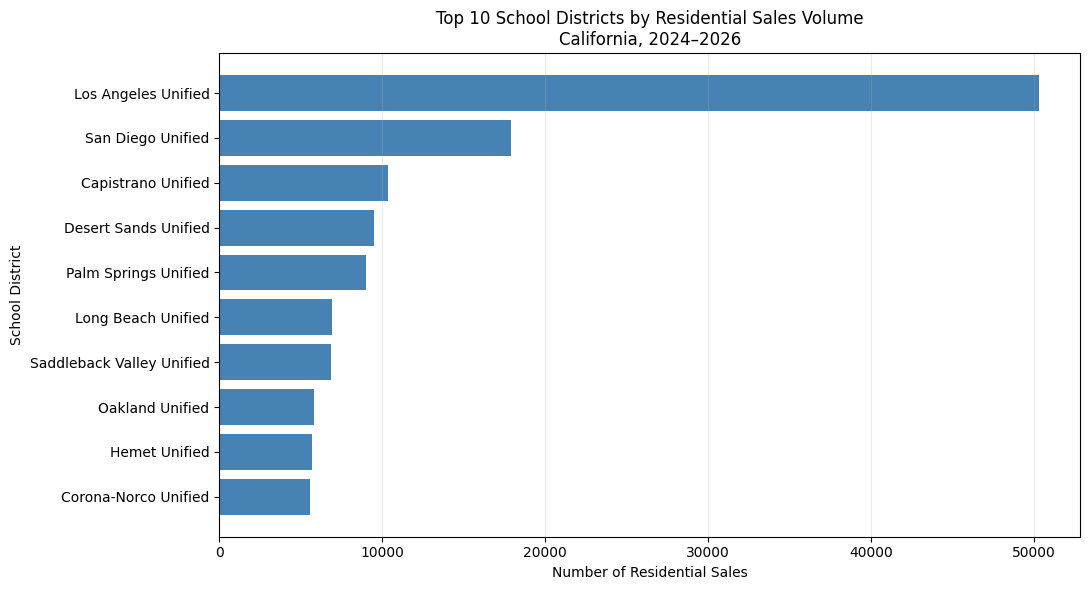

In [58]:
import matplotlib.pyplot as plt

# Select top 10 districts by total sales
top10_elementary = elementary_summary.head(10).copy()

# Create chart
plt.figure(figsize=(11, 6))

plt.barh(
    top10_elementary["ElementaryDistrict"],
    top10_elementary["TotalSales"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.title(
    "Top 10 School Districts by Residential Sales Volume\n"
    "California, 2024–2026"
)

plt.xlabel("Number of Residential Sales")
plt.ylabel("School District")

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

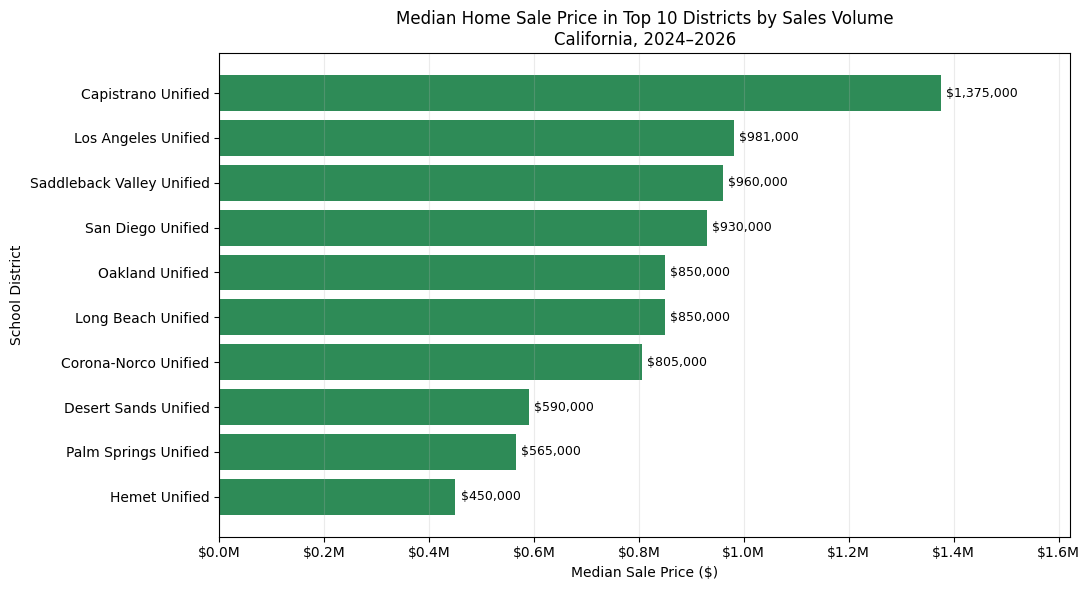

In [59]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Use the same top 10 districts by sales volume
top10_elementary = elementary_summary.head(10).copy()

# Sort by median sale price for the chart
top10_prices = top10_elementary.sort_values(
    "MedianClosePrice",
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top10_prices["ElementaryDistrict"],
    top10_prices["MedianClosePrice"],
    color="seagreen"
)

plt.title(
    "Median Home Sale Price in Top 10 Districts by Sales Volume\n"
    "California, 2024–2026"
)

plt.xlabel("Median Sale Price ($)")
plt.ylabel("School District")

# Format horizontal axis as dollars
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1_000_000:.1f}M")
)

# Display price labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 10000,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, top10_prices["MedianClosePrice"].max() * 1.18)
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

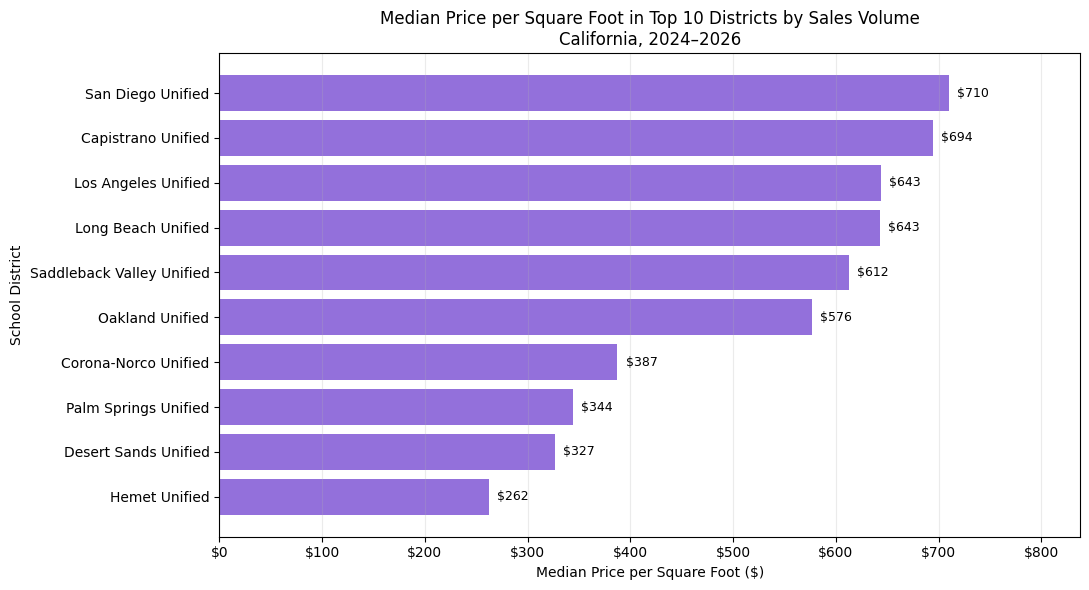

In [60]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Use the same top 10 districts by sales volume
top10_elementary = elementary_summary.head(10).copy()

# Sort by median price per square foot
top10_sqft = top10_elementary.sort_values(
    "MedianPricePerSqFt",
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top10_sqft["ElementaryDistrict"],
    top10_sqft["MedianPricePerSqFt"],
    color="mediumpurple"
)

plt.title(
    "Median Price per Square Foot in Top 10 Districts by Sales Volume\n"
    "California, 2024–2026"
)

plt.xlabel("Median Price per Square Foot ($)")
plt.ylabel("School District")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x:,.0f}")
)

# Add values to bars
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 8,
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, top10_sqft["MedianPricePerSqFt"].max() * 1.18)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

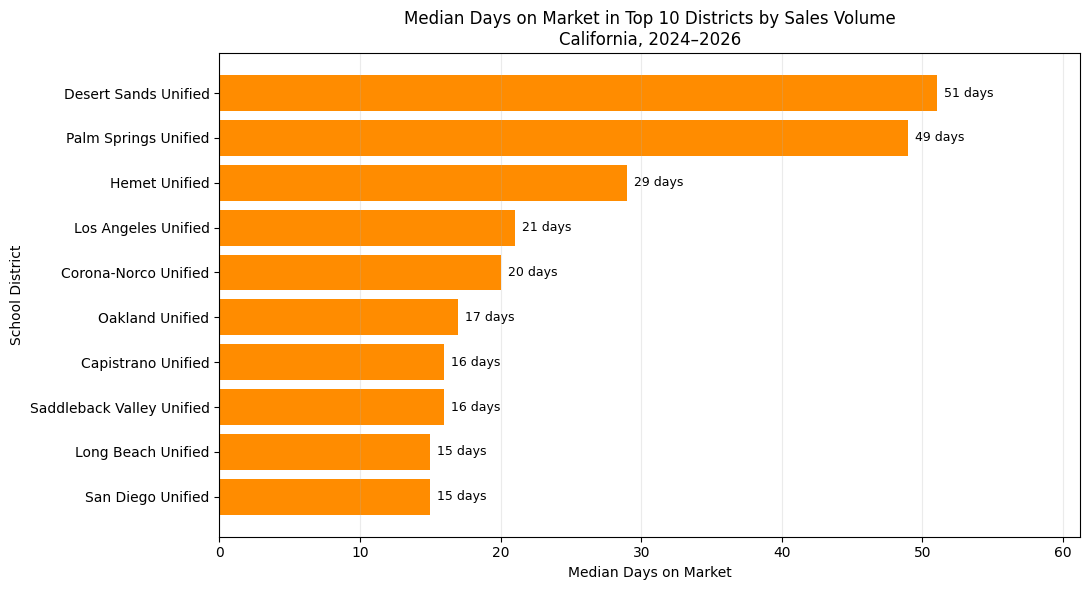

In [61]:
import matplotlib.pyplot as plt

# Use the same top 10 districts by sales volume
top10_elementary = elementary_summary.head(10).copy()

# Sort by median days on market
top10_dom = top10_elementary.sort_values(
    "MedianDaysOnMarket",
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top10_dom["ElementaryDistrict"],
    top10_dom["MedianDaysOnMarket"],
    color="darkorange"
)

plt.title(
    "Median Days on Market in Top 10 Districts by Sales Volume\n"
    "California, 2024–2026"
)

plt.xlabel("Median Days on Market")
plt.ylabel("School District")

# Add labels
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.0f} days",
        va="center",
        fontsize=9
    )

plt.xlim(0, top10_dom["MedianDaysOnMarket"].max() * 1.2)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

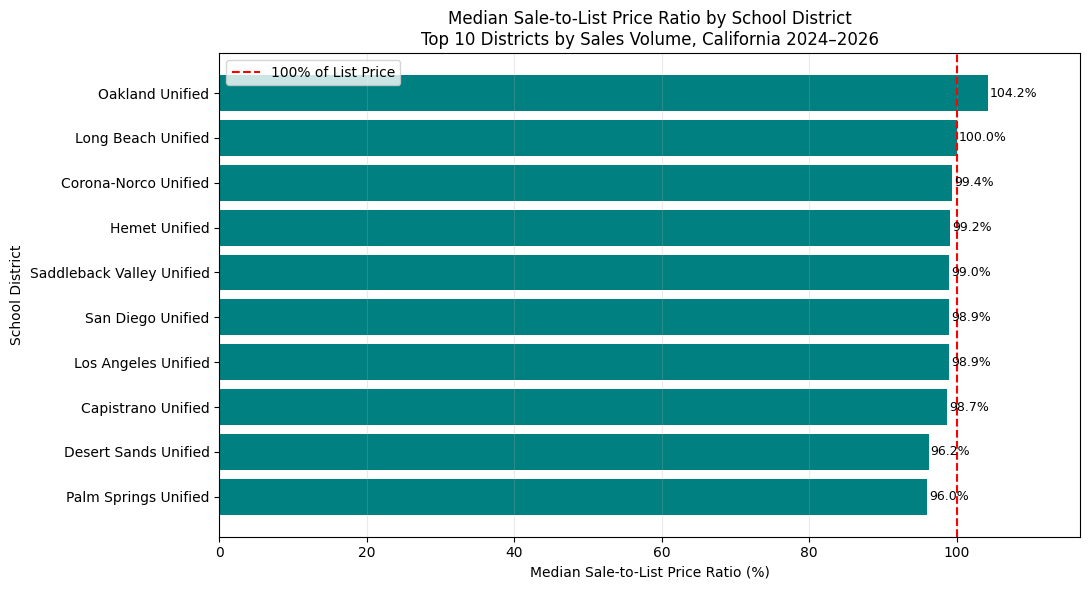

In [62]:
import matplotlib.pyplot as plt

# Use the same top 10 districts by sales volume
top10_ratio = elementary_summary.head(10).copy()

# Convert ratio to percentage
top10_ratio["MedianPriceRatioPct"] = (
    top10_ratio["MedianPriceRatio"] * 100
)

# Sort by percentage
top10_ratio = top10_ratio.sort_values(
    "MedianPriceRatioPct",
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top10_ratio["ElementaryDistrict"],
    top10_ratio["MedianPriceRatioPct"],
    color="teal"
)

# Reference line at 100%
plt.axvline(
    x=100,
    color="red",
    linestyle="--",
    label="100% of List Price"
)

plt.title(
    "Median Sale-to-List Price Ratio by School District\n"
    "Top 10 Districts by Sales Volume, California 2024–2026"
)

plt.xlabel("Median Sale-to-List Price Ratio (%)")
plt.ylabel("School District")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        fontsize=9
    )

plt.xlim(0, top10_ratio["MedianPriceRatioPct"].max() * 1.12)
plt.legend()
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [63]:
# Keep properties with a matched high school district
high_school_market = sold_w6_enriched[
    sold_w6_enriched["HighSchoolDistrictStatus"] == "Matched"
].copy()

# Calculate market metrics by high school district
high_school_summary = (
    high_school_market
    .groupby("HighSchoolDistrict_Geo")
    .agg(
        TotalSales=("PropertyRowID", "count"),
        MedianClosePrice=("ClosePrice", "median"),
        MedianPricePerSqFt=("PricePerSqFt_Valid", "median"),
        MedianDaysOnMarket=("DaysOnMarket_Valid", "median"),
        MedianPriceRatio=("PriceRatio_Valid", "median")
    )
    .reset_index()
    .sort_values("TotalSales", ascending=False)
)

# Display results
print(
    "Number of high/unified districts:",
    len(high_school_summary)
)

print(
    "Total sales included:",
    high_school_summary["TotalSales"].sum()
)

display(high_school_summary.head(10))

Number of high/unified districts: 408
Total sales included: 489739


,HighSchoolDistrict_Geo,TotalSales,MedianClosePrice,MedianPricePerSqFt,MedianDaysOnMarket,MedianPriceRatio
193,Los Angeles Unified,50322,981000.0,643.491124,21.0,0.989116
301,San Diego Unified,17937,930000.0,709.844560,15.0,0.989259
50,Capistrano Unified,10327,1375000.0,694.288914,16.0,0.986620
93,Desert Sands Unified,9487,590000.0,326.740389,51.0,0.961831
254,Palm Springs Unified,9003,565000.0,343.929378,49.0,0.960111
143,Grossmont Union High,8580,799000.0,511.522704,13.0,1.000000
264,Perris Union High,7341,575299.0,288.435250,24.0,0.998878
13,Antelope Valley Union High,7288,490000.0,276.419900,25.0,1.000000
61,Chaffey Joint Union High,7066,706000.0,423.345499,17.0,1.000000
191,Long Beach Unified,6938,850000.0,643.010753,15.0,1.000000


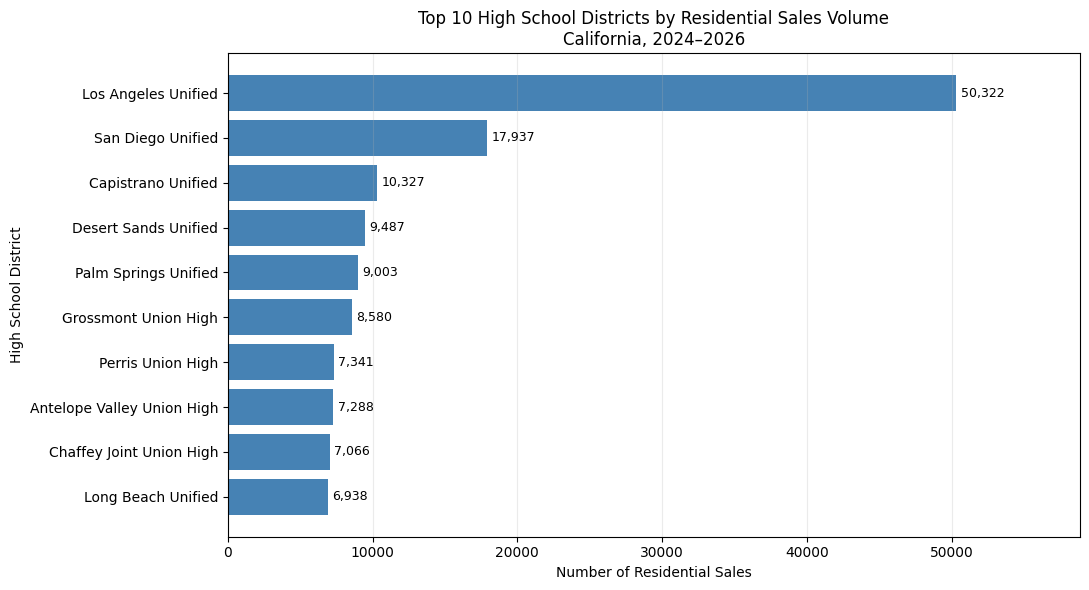

In [64]:
import matplotlib.pyplot as plt

# Select top 10 high school districts by sales volume
top10_high = high_school_summary.head(10).copy()

# Sort for horizontal chart
top10_high = top10_high.sort_values(
    "TotalSales",
    ascending=True
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top10_high["HighSchoolDistrict_Geo"],
    top10_high["TotalSales"],
    color="steelblue"
)

plt.title(
    "Top 10 High School Districts by Residential Sales Volume\n"
    "California, 2024–2026"
)

plt.xlabel("Number of Residential Sales")
plt.ylabel("High School District")

# Add sales counts
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, top10_high["TotalSales"].max() * 1.17)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

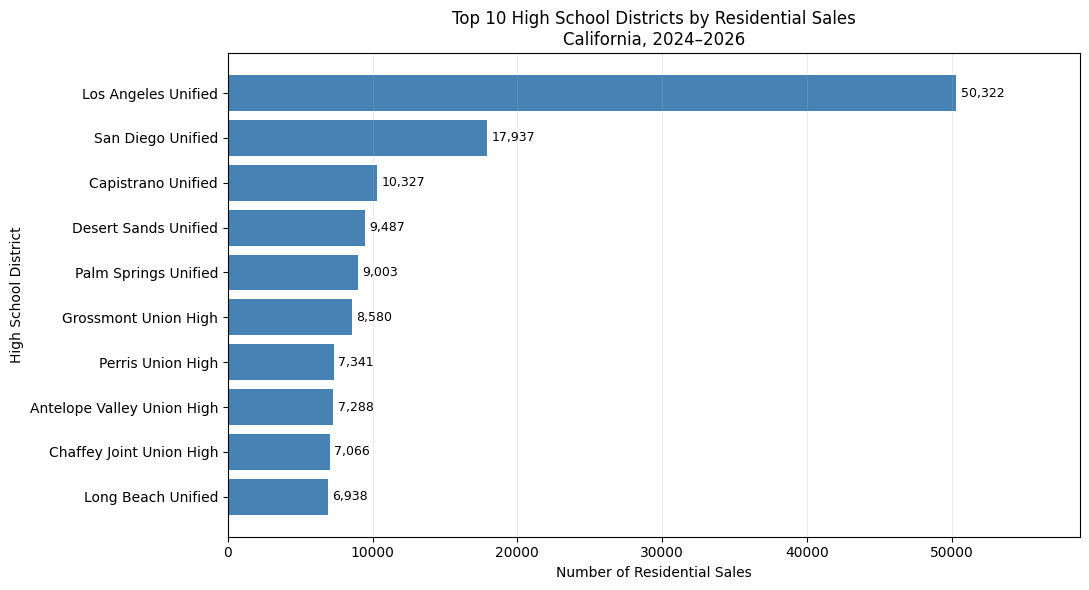

In [65]:
import matplotlib.pyplot as plt

# Top 10 high school districts by sales volume
top10_high = (
    high_school_summary
    .head(10)
    .sort_values("TotalSales", ascending=True)
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    top10_high["HighSchoolDistrict_Geo"],
    top10_high["TotalSales"],
    color="steelblue"
)

plt.title(
    "Top 10 High School Districts by Residential Sales\n"
    "California, 2024–2026"
)

plt.xlabel("Number of Residential Sales")
plt.ylabel("High School District")

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=9
    )

plt.xlim(0, top10_high["TotalSales"].max() * 1.17)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [66]:
from pathlib import Path

# Create a folder for Week 6 results
output_folder = Path("/content/Week6_Output")
output_folder.mkdir(parents=True, exist_ok=True)

# Save enriched sold dataset
sold_w6_enriched.to_csv(
    output_folder / "week6_sold_enriched.csv",
    index=False
)

# Save elementary district market summary
elementary_summary.to_csv(
    output_folder / "week6_elementary_district_summary.csv",
    index=False
)

# Save high school district market summary
high_school_summary.to_csv(
    output_folder / "week6_high_school_district_summary.csv",
    index=False
)

# Verify saved files
for file in output_folder.glob("*.csv"):
    print(
        file.name,
        "| Size:",
        round(file.stat().st_size / (1024**2), 2),
        "MB"
    )

print("\nExport completed!")

week6_sold_enriched.csv | Size: 469.41 MB
week6_elementary_district_summary.csv | Size: 0.05 MB
week6_high_school_district_summary.csv | Size: 0.03 MB

Export completed!


In [67]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create a folder for charts
chart_folder = Path("/content/Week6_Output/Charts")
chart_folder.mkdir(parents=True, exist_ok=True)

# Elementary district chart configurations
charts = {
    "elementary_sales_volume": ("TotalSales", "Residential Sales", "steelblue"),
    "elementary_median_price": ("MedianClosePrice", "Median Sale Price ($)", "seagreen"),
    "elementary_price_per_sqft": ("MedianPricePerSqFt", "Median Price per Sq Ft ($)", "mediumpurple"),
    "elementary_days_on_market": ("MedianDaysOnMarket", "Median Days on Market", "darkorange"),
    "elementary_price_ratio": ("MedianPriceRatio", "Median Sale-to-List Price Ratio (%)", "teal")
}

for filename, (column, xlabel, color) in charts.items():

    data = elementary_summary.head(10).copy()

    if column == "MedianPriceRatio":
        data[column] = data[column] * 100

    data = data.sort_values(column)

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.barh(
        data["ElementaryDistrict"],
        data[column],
        color=color
    )

    if column == "MedianPriceRatio":
        ax.axvline(100, color="red", linestyle="--")

    ax.set_title(
        xlabel + "\nTop 10 Elementary/Unified Districts by Sales Volume"
    )
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()

    fig.savefig(
        chart_folder / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

# Save high school district sales chart
data = high_school_summary.head(10).sort_values("TotalSales")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    data["HighSchoolDistrict_Geo"],
    data["TotalSales"],
    color="steelblue"
)

ax.set_title("Top 10 High/Unified Districts by Residential Sales")
ax.set_xlabel("Residential Sales")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()

fig.savefig(
    chart_folder / "high_school_sales_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

# Verify saved charts
print("Charts saved:", len(list(chart_folder.glob("*.png"))))

for file in sorted(chart_folder.glob("*.png")):
    print(file.name)

Charts saved: 6
elementary_days_on_market.png
elementary_median_price.png
elementary_price_per_sqft.png
elementary_price_ratio.png
elementary_sales_volume.png
high_school_sales_volume.png


In [68]:
import shutil
from google.colab import files

# Create ZIP containing CSV files and charts
zip_path = shutil.make_archive(
    "/content/Week6_Final_Results",
    "zip",
    "/content",
    "Week6_Output"
)

# Download ZIP to your computer
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
tables = [
    "county_summary",
    "property_summary",
    "mls_summary",
    "listing_office_clean_summary",
    "buyer_office_clean_summary",
    "office_comparison",
    "elementary_summary",
    "high_school_summary"
]

for name in tables:
    print(
        name,
        "Available" if name in globals() else "Missing"
    )

county_summary Available
property_summary Available
mls_summary Available
listing_office_clean_summary Available
buyer_office_clean_summary Available
office_comparison Available
elementary_summary Available
high_school_summary Available


In [70]:
summary_tables = {
    "County": county_summary,
    "Property Type": property_summary,
    "MLS Area": mls_summary,
    "Listing Brokerage": listing_office_clean_summary,
    "Buyer Brokerage": buyer_office_clean_summary,
    "Brokerage Comparison": office_comparison
}

for name, df in summary_tables.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))


County
Columns: ['CountyOrParish', 'TotalSales', 'MedianClosePrice', 'MedianPricePerSqFt', 'MedianDaysOnMarket', 'MedianListingToContractDays', 'MedianContractToCloseDays', 'MedianPriceRatio']
Rows: 63

Property Type
Columns: ['PropertyType', 'PropertySubType', 'TotalSales', 'MedianClosePrice', 'MedianPricePerSqFt', 'MedianDaysOnMarket', 'MedianListingToContractDays', 'MedianContractToCloseDays', 'MedianPriceRatio']
Rows: 21

MLS Area
Columns: ['CountyOrParish', 'MLSAreaMajor', 'TotalSales', 'MedianClosePrice', 'MedianPricePerSqFt', 'MedianDaysOnMarket', 'MedianPriceRatio']
Rows: 1317

Listing Brokerage
Columns: ['ListOfficeName_Normalized', 'TotalSales', 'MedianClosePrice', 'MedianDaysOnMarket', 'MedianPriceRatio']
Rows: 18818

Buyer Brokerage
Columns: ['BuyerOfficeName_Normalized', 'TotalSales', 'MedianClosePrice', 'MedianContractToCloseDays', 'MedianPriceRatio']
Rows: 21166

Brokerage Comparison
Columns: ['Brokerage', 'ListingSales', 'BuyerSales', 'CombinedSides']
Rows: 25165
